# Lesson 16. How many cameras does one splat need?

[Course plan](../../README.md)

Two orange splats look identical in a first photograph. One is small and close, the other larger and farther away. Both produce essentially zero image error. The camera moves sideways and one splat slips off the target. That shift gives the optimizer information about depth.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Two training frames and a third for checking

The left frame comes from a fixed target at depth 4, the right from the current scene. Camera positions are known in advance. Camera A sits at X = 0, B at +0.8, and the check camera at −0.6. Their axes remain parallel. The training selector chooses the images that enter the loss. The preview camera only changes the image on screen.

The model starts at depth 2.4. In camera A both images match before a single update. B sees a clear mismatch. After twenty steps on both frames, the third view improves as well, even though none of its pixels took part in the update.

In [2]:
display(demo.experiment(16, "en"))

## A family of identical first frames

The unknown depth $z>0$ is measured in world units. The model center is $(0.10z,-0.05z,z)$ and its three scales are $(0.12z,0.08z,0.06z)$. We deliberately tie six values to a single parameter. Doubling $z$ doubles the distance and the size together. Color $(0.85,0.20,0.08)$ and opacity $0.9$ stay fixed. Camera A faces $+Z$, has focal length $f=28$ pixels, and puts the center of the $33\times33$ frame at $(16,16)$.

The horizontal coordinate is $u_A=16+28\cdot0.10z/z=18.8$; the vertical coordinate is $v_A=16+28\cdot(-0.05)z/z=14.6$. The two factors of $z$ cancel in each ratio. Horizontal scale likewise contains $0.12z/z$. The footprint correction for depth extent also survives this cancellation: every entry of the Jacobian scales as $1/z$, while spatial covariance grows as $z^2$. In $J\Sigma J^\mathsf{T}$ the two divisions by $z$ cancel that square. The **whole footprint** matches, including its falloff at the edges.

At $z=2.4$, center $X=0.24$ and horizontal scale is $0.288$. At $z=4$ they are $0.40$ and $0.48$. No amount of optimization on camera A can distinguish the two scenes.

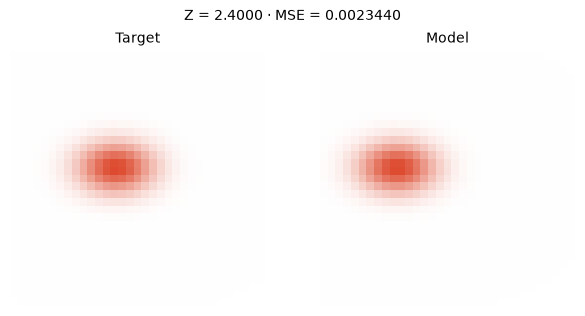

In [3]:
fig = demo.ray_figure("en")
display(fig)
plt.close(fig)

## Parallax before optimization

After camera B moves right by $b=0.8$, it sees the point at camera coordinate $X-b$. Substitution into perspective gives

$$
u_B=16+28(0.10z-b)/z=18.8-28b/z.
$$

The nearer model gives $u_B=18.8-22.4/2.4\approx9.467$, while the target gives $18.8-22.4/4=13.2$. The shift between the views is called parallax. For the target, $u_A-u_B=5.6$ pixels. Starting from $u_A-u_B=fb/z$, known $f,b$ and matching centers give depth $z=28\cdot0.8/5.6=4$. In photographs we would first have to find pixels corresponding to the same point. A Gaussian does not even have a hard edge. In the experiment we compare all the pixels of the two frames.

In [4]:
for z in [2.4, 4.0, 7.0]:
    model = sr.ray_scene(z)
    for baseline in (0, .8, -.6):
        cam = sr.translated_camera(baseline)
        uv = sr.project_splats(model, cam, 33, 33)[0]["mean"]
        print(f"Z={z:g}, Xcam={baseline:+g}: u={uv[0]:.3f}, MSE={sr.ray_loss(z,(baseline,)):.8f}")

Z=2.4, Xcam=+0: u=18.800, MSE=0.00000000
Z=2.4, Xcam=+0.8: u=9.467, MSE=0.00468808
Z=2.4, Xcam=-0.6: u=25.800, MSE=0.00277686
Z=4, Xcam=+0: u=18.800, MSE=0.00000000
Z=4, Xcam=+0.8: u=13.200, MSE=0.00000000
Z=4, Xcam=-0.6: u=23.000, MSE=0.00000000
Z=7, Xcam=+0: u=18.800, MSE=0.00000000
Z=7, Xcam=+0.8: u=15.600, MSE=0.00211890
Z=7, Xcam=-0.6: u=21.200, MSE=0.00121875


## One actual update from image error

Each camera has its own mean squared RGB difference from lesson 6, $L_A$ or $L_B$. For a single view the denominator counts $33\cdot33\cdot3=3267$ values. Initially $L_A$ is zero to numerical precision and $L_B\approx0.00468808$. With equal weight for the cameras, $L=(L_A+L_B)/2\approx0.00234404$. The held-out view never enters this sum.

There is a single unknown $z$. To check the derivative, we render two neighboring cases, $z-h$ and $z+h$, with $h=0.002$ world units. The denominator of the slope is the distance between these cases, $2h=0.004$.

$$
\begin{aligned}
g &\approx \frac{L(2.402)-L(2.398)}{0.004}\\
  &\approx (0.0023357144-0.0023523820)/0.004=-0.004167.
\end{aligned}
$$

The minus sign says that increasing depth a little decreases the loss here. With a learning rate of $\eta=80$ we get $z_{\rm new}=2.4-80(-0.004167)\approx2.73335$. The rate converts slope into a change in depth; the value 80 belongs to this particular loss scale. Depth stays within 1.25 to 7 to keep the model in front of the camera. After twenty updates $z\approx3.8101$. The held-out error falls from $0.00277686$ to $0.00001703$. Training on A alone leaves the loss curve essentially flat.

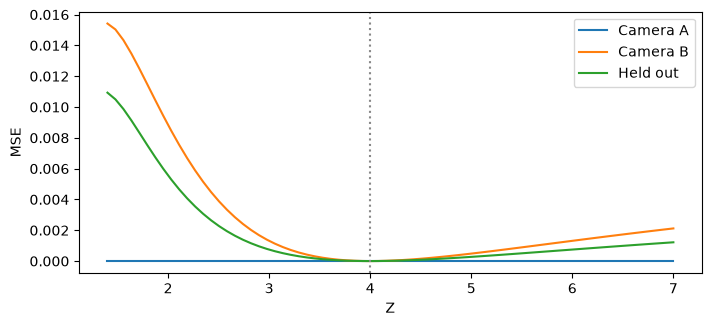

In [5]:
fig = demo.ray_landscape("en")
display(fig)
plt.close(fig)

In [6]:
z = 2.4
for step in range(20):
    z, gradient = sr.depth_step(z, (0,.8))
print(round(z, 6), sr.ray_loss(z, (0,.8)), sr.ray_loss(z, (-.6,)))
assert sr.ray_loss(z, (-.6,)) < sr.ray_loss(2.4, (-.6,))

3.810089 1.5238536519958356e-05 1.70260316191234e-05


## From one parameter to a scene with two Gaussians

Now we untie position from width. In a separate experiment two splats have independent centers and RGB values, six numbers each. Their scales, rotations, opacities, and camera calibration are known. Two color images come from cameras at $X=-0.8$ and $+0.65$. A third camera at $+0.12$ supplies a check view. All three panels below use that camera.

The program computes footprints, blends them and averages errors over **only the first two** frames. In PyTorch a computation graph connects color and center to every rendered pixel. Calling `backward()` gives each of the 12 numbers the rate of change of the shared loss, as in lesson 8. Adam chooses the steps here. It keeps running estimates of each parameter's gradient and squared gradient to adjust the size of its update. The sorted layer indices stay fixed within a step; an order swap itself is discrete. After an update RGB stays within zero to one and depth within 1.25 to 7.

Training starts with inaccurate centers and muted colors. Across 45 steps the held-out MSE drops from about $0.002427$ to $0.00000827$. Low error on another image checks the prediction at that particular view. Hidden details and unobserved sides still have no measurements.

In [7]:
import torch
from splat_fit import train_two_splats
torch.set_num_threads(1)
run = train_two_splats(45)
print(np.array(run["history"])[[0, 15, 45]])
assert run["history"][-1][1] < run["history"][0][1] / 100

[[2.35787013e-03 2.42663412e-03]
 [1.26140177e-04 1.16656163e-04]
 [9.42653280e-06 8.26944021e-06]]


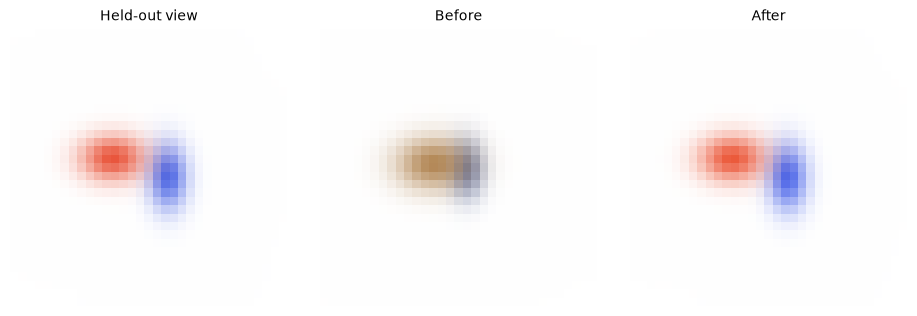

In [8]:
fig = demo.panel([run["target"],run["before"],run["after"]], ["Held-out view","Before","After"])
display(fig)
plt.close(fig)

## Experiments and worked answers

Would a second photograph from precisely the same position help once the first view matches? How distinguishable are the depths with a very small baseline?

<details><summary>Worked answer</summary>

A duplicate of A doubles the number of measurements and the denominator of the average, leaving the same flat dependence on depth. With $b=0.008$ instead of $0.8$, the center discrepancy between the 2.4 and 4 hypotheses is only $3.733/100\approx0.037$ pixels. A difference still exists in theory. In photographs it is easier to lose to noise, blur, and pose error.

</details>